In [25]:
!pip install captum transformers sentencepiece -q

In [26]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.model_selection import train_test_split
from captum.attr import IntegratedGradients, visualization
from IPython.display import display, HTML
from tqdm import tqdm
import re
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [ ]:
MODEL_NAME  = 'xlm-roberta-large'
CKPT_PATH   = '/kaggle/input/models/vladcvx/cil-roberta-5-epochs/pytorch/default/1/best_model_num_epochs-5lr-1e-06warmup_ratio-0.1train_size-226800val_size-25200time-20260521-100628.pth'
DATA_DIR    = '/kaggle/input/datasets/vladcvx/sentiment-classification-data-256-roberta/data1'
PLOTS_DIR   = '/kaggle/working/ig_plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

LABEL_NAMES       = ['1 star', '2 stars', '3 stars', '4 stars', '5 stars']
SAMPLES_PER_CLASS = 5
MAX_LENGTH        = 256
IG_N_STEPS        = 300
VAL_SIZE          = 0.10

In [28]:
def split_title_body(text: str):
    parts = text.split('\n\n', 1)
    if len(parts) == 2:
        return parts[0].strip(), parts[1].strip()
    return text.strip(), ''

def preprocess(text: str):
    title, body = split_title_body(text)
    title = re.sub(r'\s+', ' ', title).strip()
    body  = re.sub(r'\s+', ' ', body).strip()
    return title, body

train_df = pd.read_csv(f'{DATA_DIR}/train.csv')

_, val_df = train_test_split(
    train_df,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=train_df['label'],
)
val_df = val_df.reset_index(drop=True)
val_df[['title', 'body']] = val_df['sentence'].apply(
    lambda t: pd.Series(preprocess(t))
)
print(f'Val set: {len(val_df):,} rows')

Val set: 25,200 rows


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)
state_dict = torch.load(CKPT_PATH, map_location=device)
if all(k.startswith('module.') for k in state_dict.keys()):
    state_dict = {k[len('module.'):]: v for k, v in state_dict.items()}
model.load_state_dict(state_dict)
model = model.to(device)
model.eval()
print('Model loaded.')

BOS_ID = tokenizer.bos_token_id  # <s>
EOS_ID = tokenizer.eos_token_id  # </s>
PAD_ID = tokenizer.pad_token_id  # <pad>
print(f'BOS={BOS_ID}  EOS={EOS_ID}  PAD={PAD_ID}')

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded.
BOS=0  EOS=2  PAD=1


In [ ]:
# class RobertaEmbeddingWrapper(nn.Module):
#     def __init__(self, model):
#         super().__init__()
#         self.model = model

#     def forward(self, embeddings, attention_mask, target_class):
#         outputs = self.model.roberta.encoder(
#             embeddings,
#             attention_mask=self._get_extended_mask(attention_mask, embeddings.dtype),
#         )
#         sequence_output = outputs.last_hidden_state
#         pooled = self.model.roberta.pooler(sequence_output)
#         pooled = self.model.dropout(pooled)
#         logits = self.model.classifier(pooled)
#         probs  = F.softmax(logits, dim=1)
#         return probs[:, target_class]

#     def _get_extended_mask(self, attention_mask, dtype):
#         extended = attention_mask[:, None, None, :]
#         extended = extended.to(dtype=dtype)
#         extended = (1.0 - extended) * torch.finfo(dtype).min
#         return extended

#     def get_embeddings(self, input_ids):
#         return self.model.roberta.embeddings(input_ids)

class RobertaEmbeddingWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, embeddings, attention_mask, target_class):
        outputs = self.model(
            inputs_embeds=embeddings,
            attention_mask=attention_mask
        )
        logits = outputs.logits
        # probs = F.softmax(logits, dim=1)
        
        # return probs[:, target_class]
        return logits[:, target_class]

    def get_embeddings(self, input_ids):
        return self.model.roberta.embeddings.word_embeddings(input_ids)


wrapper = RobertaEmbeddingWrapper(model)
wrapper.eval()

ig = IntegratedGradients(
    lambda emb, attn, tc: wrapper(emb, attn, tc)
)
print('Wrapper ready.')

Wrapper ready.


In [ ]:
def predict_single(title, body):
    enc = tokenizer(
        title, body if body else ' ',
        truncation=True, padding=True,
        max_length=MAX_LENGTH, return_tensors='pt'
    )
    enc = {k: v.to(device) for k, v in enc.items()}
    with torch.no_grad():
        logits = model(**enc).logits
    probs = F.softmax(logits, dim=1).cpu().numpy()[0]
    return probs

print('Running inference on val set...')
val_preds, val_confs = [], []
for _, row in tqdm(val_df.iterrows(), total=len(val_df)):
    probs = predict_single(row['title'], row['body'])
    val_preds.append(probs.argmax())
    val_confs.append(probs.max())

val_df['pred']    = val_preds
val_df['conf']    = val_confs
val_df['correct'] = (val_df['pred'] == val_df['label'])

mae = np.mean(np.abs(np.array(val_preds) - val_df['label'].values))
print(f'Val score: {1 - mae/4:.4f}')

Running inference on val set...


100%|██████████| 25200/25200 [09:19<00:00, 45.05it/s]

Val score: 0.9081


In [32]:
def sample_per_class(df, n_correct, n_incorrect, seed=SEED):
    samples = []
    for label in range(5):
        cls_df = df[df['label'] == label]
        correct   = cls_df[cls_df['correct']].sample(
            min(n_correct,   len(cls_df[cls_df['correct']])),   random_state=seed)
        incorrect = cls_df[~cls_df['correct']].sample(
            min(n_incorrect, len(cls_df[~cls_df['correct']])),  random_state=seed)
        for _, row in correct.iterrows():
            samples.append({**row.to_dict(), 'split': 'correct'})
        for _, row in incorrect.iterrows():
            samples.append({**row.to_dict(), 'split': 'incorrect'})
    return samples

samples = sample_per_class(val_df, n_correct=SAMPLES_PER_CLASS, n_incorrect=SAMPLES_PER_CLASS)
print(f'Total samples: {len(samples)}')
for label in range(5):
    cls = [s for s in samples if s['label'] == label]
    print(f'  {LABEL_NAMES[label]}: '
          f'{sum(1 for s in cls if s["split"]=="correct")} correct, '
          f'{sum(1 for s in cls if s["split"]=="incorrect")} incorrect')

Total samples: 50
  1 star: 5 correct, 5 incorrect
  2 stars: 5 correct, 5 incorrect
  3 stars: 5 correct, 5 incorrect
  4 stars: 5 correct, 5 incorrect
  5 stars: 5 correct, 5 incorrect


In [ ]:
def compute_ig(title, body, target_class, n_steps=IG_N_STEPS):

    enc = tokenizer(
        title, body if body else ' ',
        truncation=True, padding=False,
        max_length=MAX_LENGTH, return_tensors='pt'
    )
    input_ids = enc['input_ids'].to(device)
    attention_mask = enc['attention_mask'].to(device)
    seq_len = input_ids.shape[1]

    baseline_ids = torch.full_like(input_ids, PAD_ID) 
    baseline_ids[0, 0]       = BOS_ID
    baseline_ids[0, seq_len - 1] = EOS_ID
    if seq_len > 2:
        eos_positions = (input_ids[0] == EOS_ID).nonzero(as_tuple=True)[0]
        for pos in eos_positions:
            baseline_ids[0, pos] = EOS_ID

    input_emb = wrapper.get_embeddings(input_ids)
    baseline_emb = wrapper.get_embeddings(baseline_ids)

    target_class_tensor = torch.tensor(target_class, device=device)

    attributions, delta = ig.attribute(
        inputs=input_emb,
        baselines=baseline_emb,
        additional_forward_args=(attention_mask, target_class_tensor),
        n_steps=n_steps,
        internal_batch_size=2,
        return_convergence_delta=True,
    )

    attr_sum  = attributions.sum(dim=2).squeeze(0)
    attr_norm = attr_sum / (torch.norm(attr_sum) + 1e-8)
    attr_list = attr_norm.cpu().detach().numpy().tolist()

    tokens = tokenizer.convert_ids_to_tokens(input_ids[0].cpu().numpy().tolist())
    return tokens, attr_list, delta.item()


print('Computing IG attributions...')
ig_results = []
for s in tqdm(samples):
    title = s['title']
    body = s['body']
    pred_class = int(s['pred'])

    try:
        tokens, attrs, delta = compute_ig(title, body, target_class=pred_class)
        ig_results.append({
            'sentence'  : s['sentence'],
            'true_label': int(s['label']),
            'pred_label': pred_class,
            'correct'   : s['split'] == 'correct',
            'conf'      : float(s['conf']),
            'tokens'    : tokens,
            'attrs'     : attrs,
            'delta'     : delta,
        })
    except Exception as e:
        print(f'Failed for sample: {e}')

print(f'Done — {len(ig_results)} attributions computed.')

Computing IG attributions...


100%|██████████| 50/50 [08:53<00:00, 10.66s/it]

Done — 50 attributions computed.


In [ ]:
vis_records = []

for r in ig_results:
    tokens = r['tokens']
    attrs = r['attrs']
    n = len(tokens)

    record = visualization.VisualizationDataRecord(
        word_attributions  = attrs,
        pred_prob          = r['conf'],
        pred_class         = LABEL_NAMES[r['pred_label']],
        true_class         = LABEL_NAMES[r['true_label']],
        attr_class         = LABEL_NAMES[r['pred_label']],
        attr_score         = sum(attrs),
        raw_input_ids      = tokens[:n],
        convergence_score  = r['delta'],
    )
    vis_records.append(record)

visualization.visualize_text(vis_records)

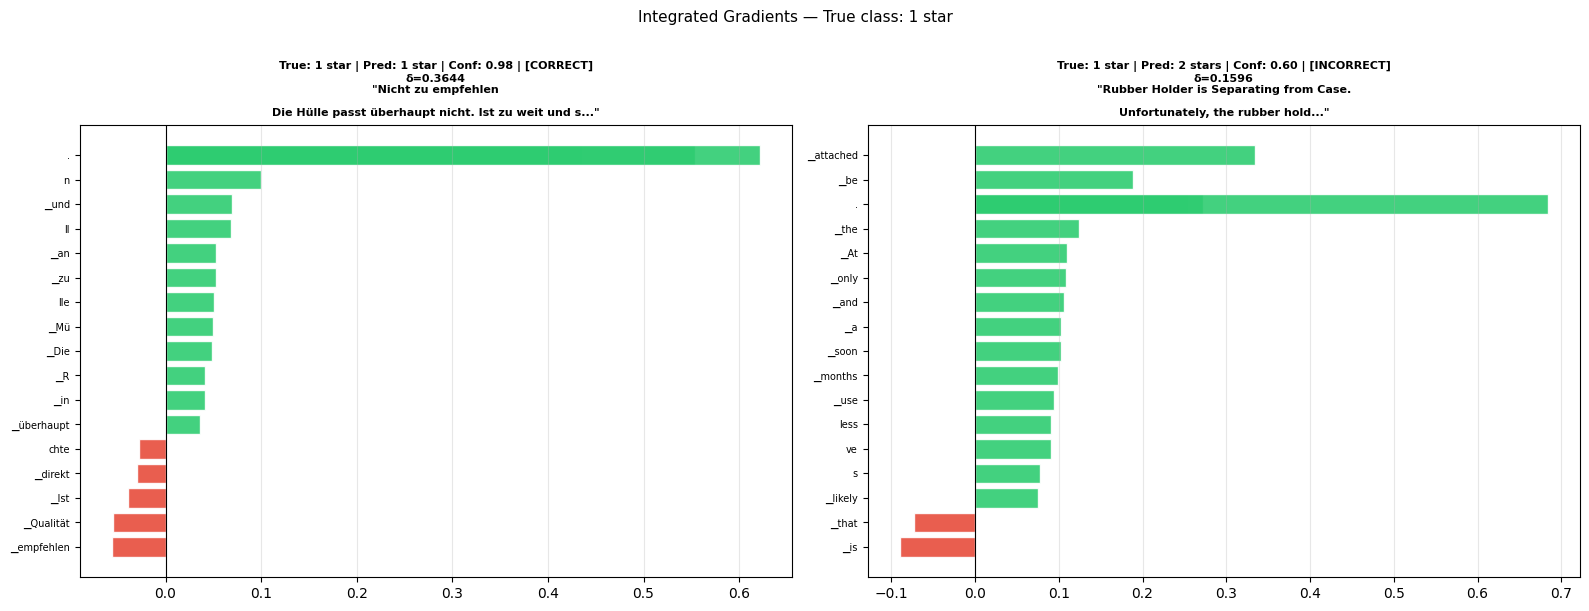

Saved: /kaggle/working/ig_plots/ig_class0_1_star.png


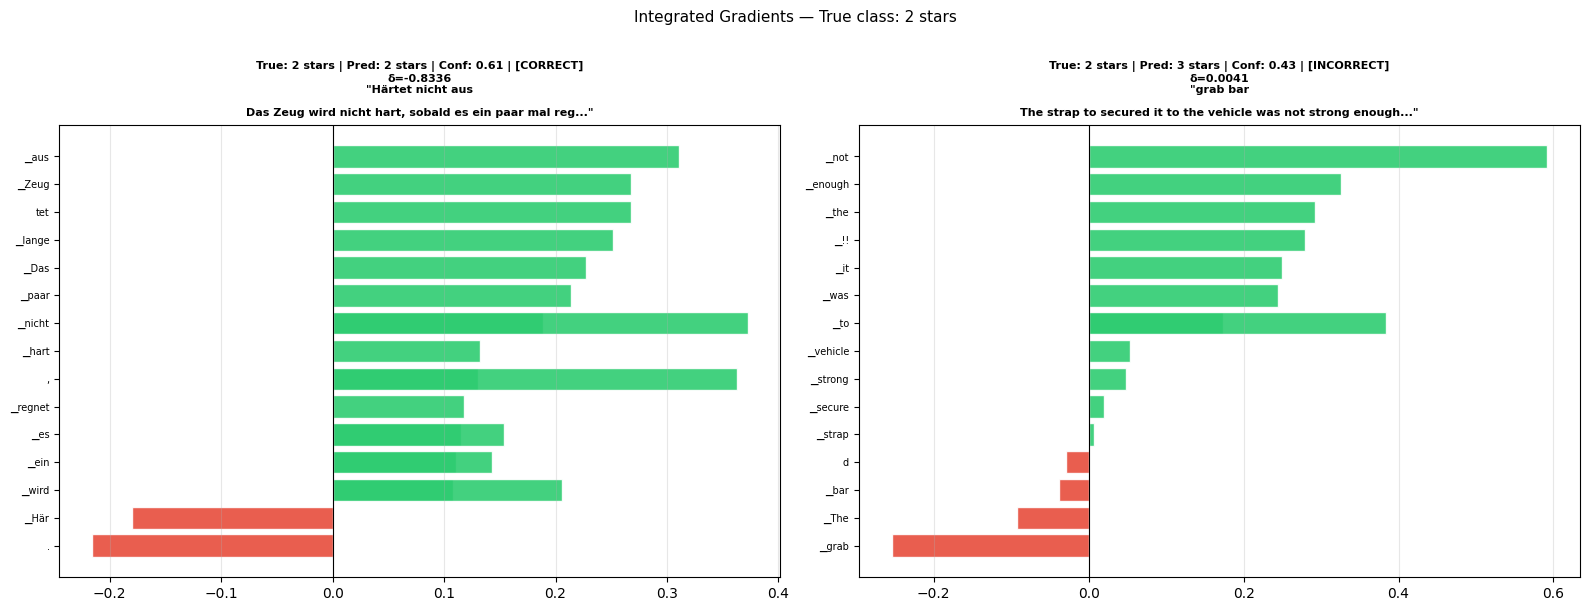

Saved: /kaggle/working/ig_plots/ig_class1_2_stars.png


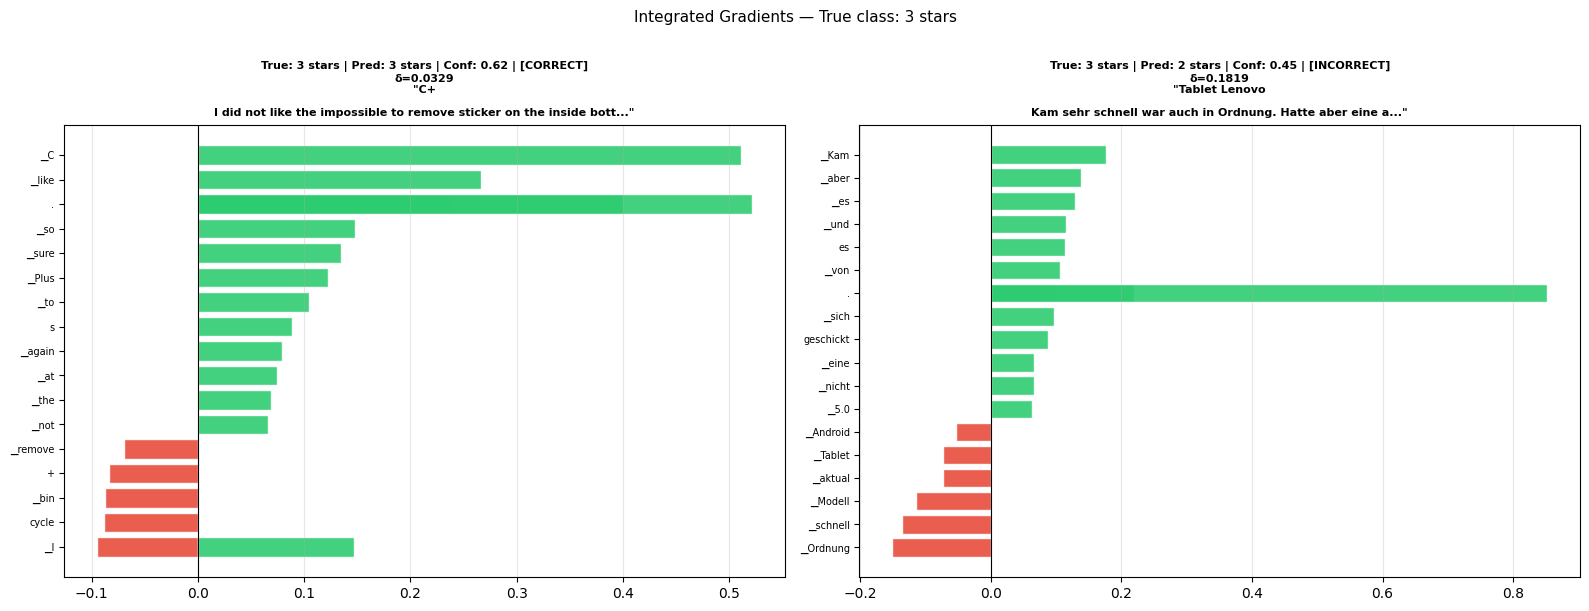

Saved: /kaggle/working/ig_plots/ig_class2_3_stars.png


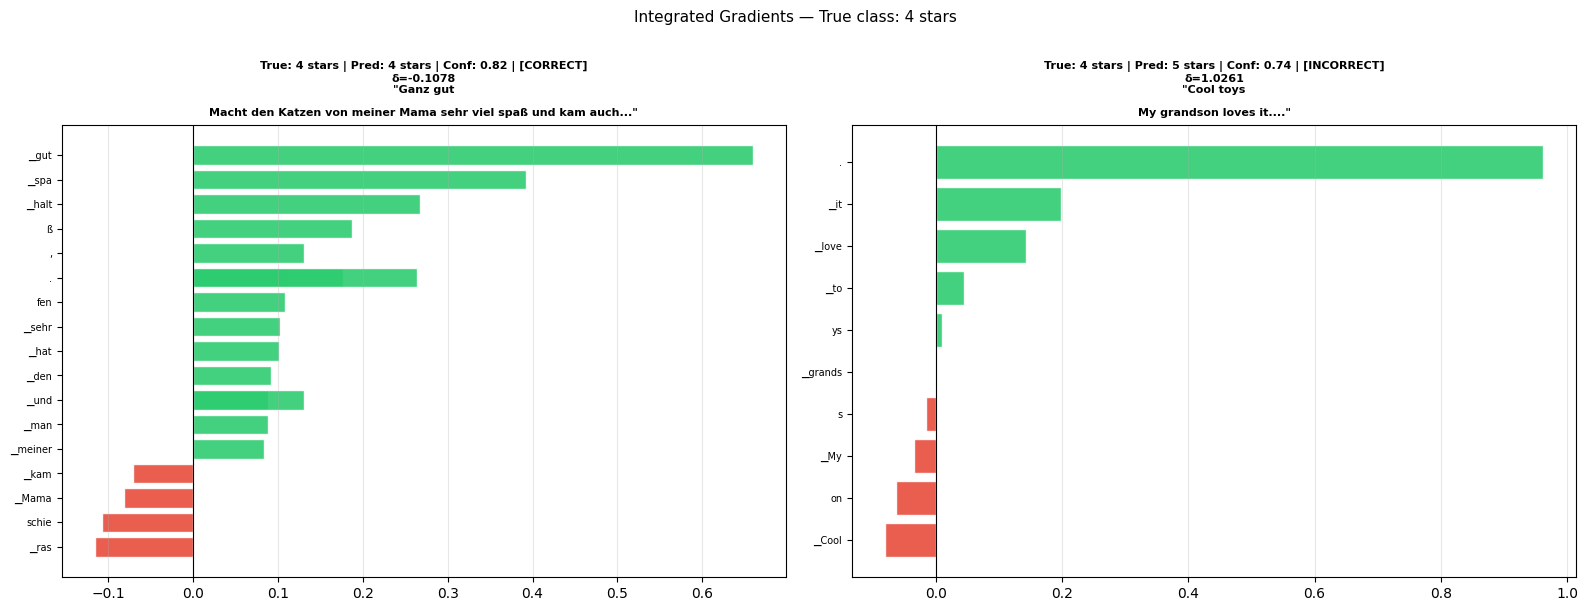

Saved: /kaggle/working/ig_plots/ig_class3_4_stars.png


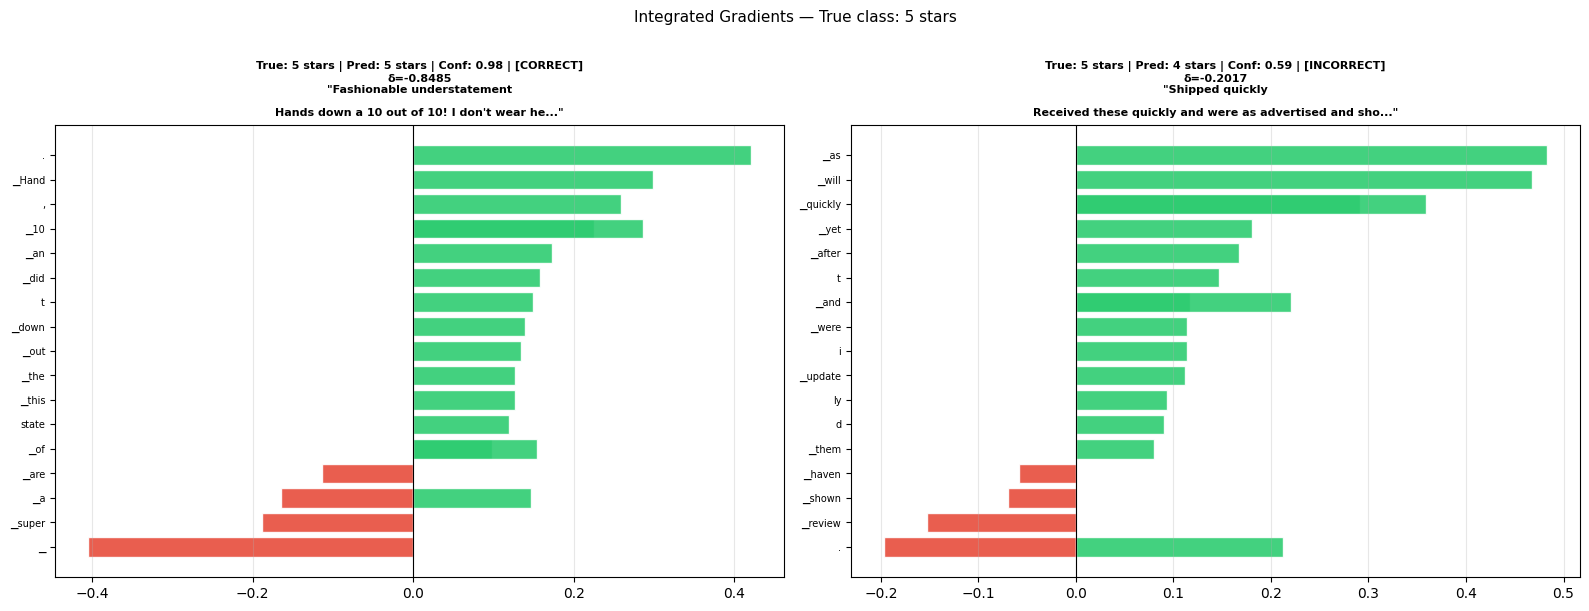

Saved: /kaggle/working/ig_plots/ig_class4_5_stars.png


In [ ]:
import matplotlib.pyplot as plt

def plot_ig_bar(tokens, attrs, title, ax, n_tokens=20):
    """Show top-N tokens by |attribution|, coloured by sign."""
    skip = {'<s>', '</s>', '<pad>'}
    filtered = [(t, a) for t, a in zip(tokens, attrs) if t not in skip]
    top = sorted(filtered, key=lambda x: abs(x[1]), reverse=True)[:n_tokens]
    top = sorted(top, key=lambda x: x[1])
    words  = [t for t, _ in top]
    values = [a for _, a in top]
    colors = ['#2ecc71' if v > 0 else '#e74c3c' for v in values]
    ax.barh(words, values, color=colors, edgecolor='white', alpha=0.9)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontsize=8, fontweight='bold')
    ax.tick_params(axis='y', labelsize=7)
    ax.grid(axis='x', alpha=0.3)

for label in range(5):
    cls_results = [r for r in ig_results if r['true_label'] == label]
    correct_res   = [r for r in cls_results if r['correct']]
    incorrect_res = [r for r in cls_results if not r['correct']]

    to_show = []
    if correct_res: to_show.append(('correct',   correct_res[0]))
    if incorrect_res: to_show.append(('incorrect', incorrect_res[0]))
    if not to_show: continue

    fig, axes = plt.subplots(1, len(to_show), figsize=(8 * len(to_show), 6))
    if len(to_show) == 1:
        axes = [axes]

    for ax, (split, r) in zip(axes, to_show):
        title_str = (
            f'True: {LABEL_NAMES[r["true_label"]]} | '
            f'Pred: {LABEL_NAMES[r["pred_label"]]} | '
            f'Conf: {r["conf"]:.2f} | [{split.upper()}]\n'
            f'δ={r["delta"]:.4f}\n'
            f'"{r["sentence"][:70]}..."'
        )
        plot_ig_bar(r['tokens'], r['attrs'], title_str, ax)

    plt.suptitle(f'Integrated Gradients - True class: {LABEL_NAMES[label]}',
                 fontsize=11, y=1.01)
    plt.tight_layout()
    fname = f'{PLOTS_DIR}/ig_class{label}_{LABEL_NAMES[label].replace(" ","_")}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {fname}')

In [37]:
!zip ig_plots.zip -r /kaggle/working/ig_plots

  adding: kaggle/working/ig_plots/ (stored 0%)
  adding: kaggle/working/ig_plots/ig_class3_4_stars.png (deflated 22%)
  adding: kaggle/working/ig_plots/ig_class1_2_stars.png (deflated 22%)
  adding: kaggle/working/ig_plots/ig_class0_1_star.png (deflated 22%)
  adding: kaggle/working/ig_plots/ig_class4_5_stars.png (deflated 21%)
  adding: kaggle/working/ig_plots/ig_class2_3_stars.png (deflated 22%)
